1.import libraries

In [5]:

# =====================================================
# 1. DATA MANIPULATION
# =====================================================
import pandas as pd
import numpy as np

# =====================================================
# 2. DATA VISUALIZATION
# =====================================================
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# 3. TEXT PREPROCESSING
# =====================================================
import re
import string

# =====================================================
# 4. DATASET SPLITTING
# =====================================================
from sklearn.model_selection import train_test_split

# =====================================================
# 5. DEEP LEARNING - TENSORFLOW AND KERAS
# =====================================================
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# =====================================================
# 6. MODEL ARCHITECTURE
# =====================================================
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Dense,
    Dropout
)

# =====================================================
# 7. MODEL OPTIMIZATION
# =====================================================
from tensorflow.keras.optimizers import Adam

# =====================================================
# 8. KERAS CALLBACKS
# =====================================================
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    TensorBoard
)

# =====================================================
# 9. MODEL EVALUATION
# =====================================================
from sklearn.metrics import accuracy_score

# =====================================================
# 10. FILE AND MODEL MANAGEMENT
# =====================================================
import os
import pickle

# =====================================================
# IMPORT VERIFICATION
# =====================================================
print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)


All libraries imported successfully!
TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Pandas Version: 2.2.3


In [6]:
tf.keras.utils.set_random_seed(256)
np.random.seed(256)

2.load the data set

In [7]:
# Upload dataset directly from your system
from google.colab import files

uploaded = files.upload()

# Load CSV file
file_name = next(iter(uploaded))

df = pd.read_csv(file_name, encoding="cp1252")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving Articles.csv to Articles (1).csv
Dataset loaded successfully!
Dataset Shape: (2692, 4)


,Article,Date,Heading,NewsType
0,KARACHI: The Sindh government has decided to b...,1/1/2015,sindh govt decides to cut public transport far...,business
1,HONG KONG: Asian markets started 2015 on an up...,1/2/2015,asia stocks up in new year trad,business
2,HONG KONG: Hong Kong shares opened 0.66 perce...,1/5/2015,hong kong stocks open 0.66 percent lower,business
3,HONG KONG: Asian markets tumbled Tuesday follo...,1/6/2015,asian stocks sink euro near nine year,business
4,NEW YORK: US oil prices Monday slipped below $...,1/6/2015,us oil prices slip below 50 a barr,business


Step 3: Exploratory Data Analysis (EDA).

========== DATASET OVERVIEW ==========
Dataset Shape: (2692, 4)

Column Names:
['Article', 'Date', 'Heading', 'NewsType']

First 5 Records:


,Article,Date,Heading,NewsType
0,KARACHI: The Sindh government has decided to b...,1/1/2015,sindh govt decides to cut public transport far...,business
1,HONG KONG: Asian markets started 2015 on an up...,1/2/2015,asia stocks up in new year trad,business
2,HONG KONG: Hong Kong shares opened 0.66 perce...,1/5/2015,hong kong stocks open 0.66 percent lower,business
3,HONG KONG: Asian markets tumbled Tuesday follo...,1/6/2015,asian stocks sink euro near nine year,business
4,NEW YORK: US oil prices Monday slipped below $...,1/6/2015,us oil prices slip below 50 a barr,business



========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2692 entries, 0 to 2691
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Article   2692 non-null   object
 1   Date      2692 non-null   object
 2   Heading   2692 non-null   object
 3   NewsType  2692 non-null   object
dtypes: object(4)
memory usage: 84.3+ KB

========== MISSING VALUES ==========
Article     0
Date        0
Heading     0
NewsType    0
dtype: int64

Total Missing Values: 0

========== DUPLICATE RECORDS ==========
Duplicate Rows: 107
Duplicate Articles: 108

========== UNIQUE VALUES ==========
Article: 2584 unique values
Date: 666 unique values
Heading: 2581 unique values
NewsType: 2 unique values

========== ARTICLE TEXT ANALYSIS ==========

Word Count Statistics:
count    2692.000000
mean      291.273403
std       173.757545
min        32.000000
25%       166.000000
50%       263.500000
75%       381.000000
max   

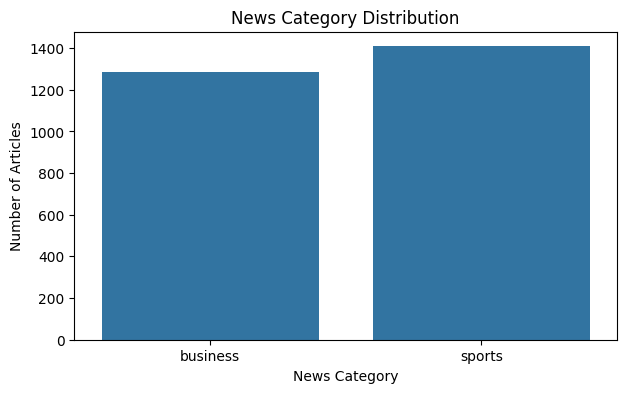

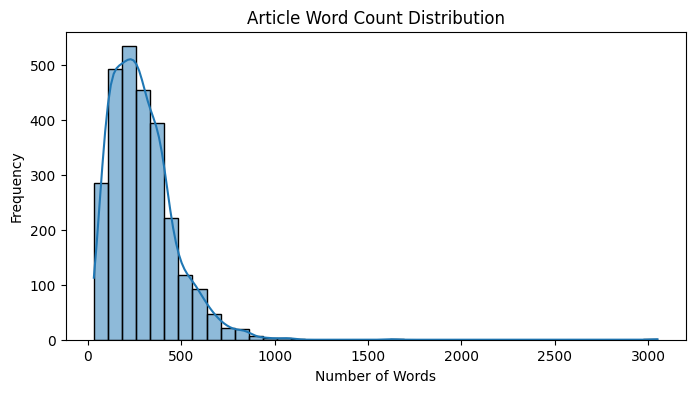

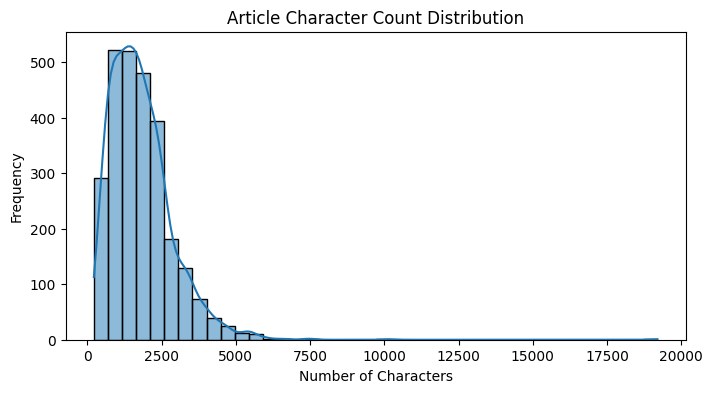

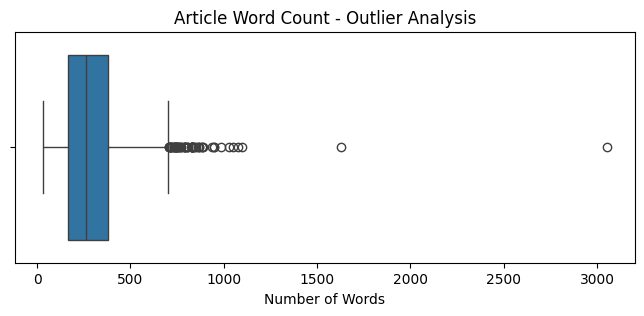

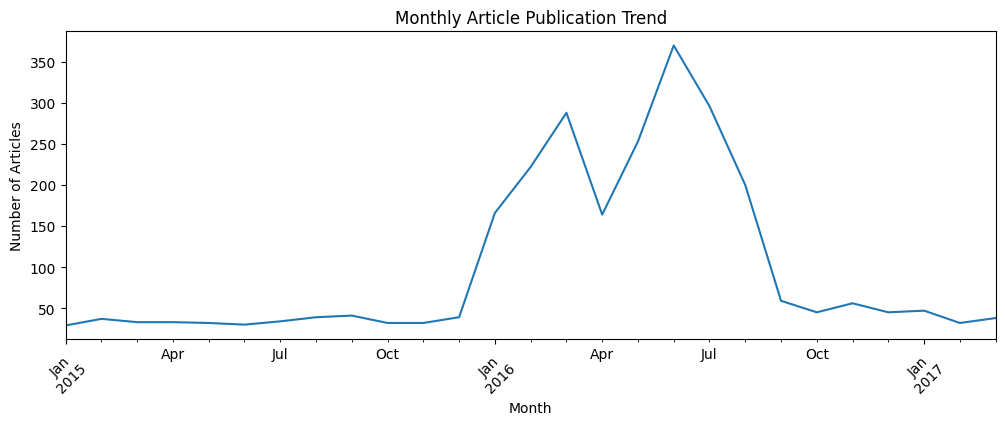


========== EDA COMPLETED SUCCESSFULLY ==========


In [8]:

# =====================================================
# STEP 3: EXPLORATORY DATA ANALYSIS (EDA)
# =====================================================

# 1. Dataset overview
print("========== DATASET OVERVIEW ==========")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

# 2. Dataset information
print("\n========== DATASET INFORMATION ==========")
df.info()

# 3. Missing values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# 4. Duplicate records
print("\n========== DUPLICATE RECORDS ==========")

print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Articles:", df["Article"].duplicated().sum())

# 5. Unique values
print("\n========== UNIQUE VALUES ==========")

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")

# 6. Article text analysis
print("\n========== ARTICLE TEXT ANALYSIS ==========")

df["word_count"] = df["Article"].astype(str).apply(
    lambda text: len(text.split())
)

df["character_count"] = df["Article"].astype(str).apply(len)

print("\nWord Count Statistics:")
print(df["word_count"].describe())

print("\nCharacter Count Statistics:")
print(df["character_count"].describe())

print("\nEmpty Articles:",
      df["Article"].astype(str).str.strip().eq("").sum())

# 7. News category distribution
print("\n========== NEWS CATEGORY DISTRIBUTION ==========")
print(df["NewsType"].value_counts())

print("\nCategory Percentage:")
print(df["NewsType"].value_counts(normalize=True) * 100)

# 8. Date analysis
print("\n========== DATE ANALYSIS ==========")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Earliest Date:", df["Date"].min())
print("Latest Date:", df["Date"].max())
print("Invalid Dates:", df["Date"].isna().sum())

# =====================================================
# VISUALIZATION
# =====================================================

# 9. News category distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="NewsType")
plt.title("News Category Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.show()

# 10. Article word count distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["word_count"], bins=40, kde=True)
plt.title("Article Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# 11. Article character count distribution
plt.figure(figsize=(8, 4))
sns.histplot(df["character_count"], bins=40, kde=True)
plt.title("Article Character Count Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

# 12. Boxplot for article word counts
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["word_count"])
plt.title("Article Word Count - Outlier Analysis")
plt.xlabel("Number of Words")
plt.show()

# 13. Articles published over time
articles_per_date = df.groupby(
    df["Date"].dt.to_period("M")
).size()

plt.figure(figsize=(12, 4))
articles_per_date.plot()
plt.title("Monthly Article Publication Trend")
plt.xlabel("Month")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

print("\n========== EDA COMPLETED SUCCESSFULLY ==========")


Step 4 – Complete Data Cleaning and Text Preprocessing

In [9]:
# ============================================
# STEP 4: DATA CLEANING AND TEXT PREPROCESSING
# ============================================

import re
import pandas as pd
import numpy as np

# 1. Check original dataset shape
print("Original Dataset Shape:", df.shape)

# 2. Check missing values
print("\nMissing Values Before Cleaning:")
print(df["Article"].isnull().sum())

# 3. Remove missing articles
df = df.dropna(subset=["Article"]).copy()

# 4. Convert article text into string
df["Article"] = df["Article"].astype(str)

# 5. Convert text to lowercase
df["Article"] = df["Article"].str.lower()

# 6. Remove duplicate articles
df = df.drop_duplicates(subset=["Article"]).copy()

# 7. Remove unwanted special characters
df["Article"] = df["Article"].apply(
    lambda text: re.sub(r"[^a-zA-Z0-9\s.,!?;:'-]", "", text)
)

# 8. Remove extra whitespaces
df["Article"] = df["Article"].apply(
    lambda text: re.sub(r"\s+", " ", text).strip()
)

# 9. Remove empty articles
df = df[df["Article"].str.strip() != ""].copy()

# 10. Reset dataset index
df = df.reset_index(drop=True)

# 11. Final dataset verification
print("\n========== DATA CLEANING SUMMARY ==========")

print("Final Dataset Shape:", df.shape)

print("Total Articles:", len(df))

print("Missing Values:", df["Article"].isnull().sum())

print("Duplicate Articles:", df["Article"].duplicated().sum())

print("Empty Articles:", (df["Article"].str.strip() == "").sum())

# 12. Display cleaned article samples
print("\n========== CLEANED ARTICLE SAMPLES ==========")

for i in range(min(3, len(df))):
    print(f"\nArticle {i+1}:")
    print(df["Article"].iloc[i][:500])

print("\nSTEP 4: DATA CLEANING COMPLETED SUCCESSFULLY!")

Original Dataset Shape: (2692, 6)

Missing Values Before Cleaning:
0

========== DATA CLEANING SUMMARY ==========
Final Dataset Shape: (2584, 6)
Total Articles: 2584
Missing Values: 0
Duplicate Articles: 0
Empty Articles: 0

========== CLEANED ARTICLE SAMPLES ==========

Article 1:
karachi: the sindh government has decided to bring down public transport fares by 7 per cent due to massive reduction in petroleum product prices by the federal government, geo news reported.sources said reduction in fares will be applicable on public transport, rickshaw, taxi and other means of traveling.meanwhile, karachi transport ittehad kti has refused to abide by the government decision.kti president irshad bukhari said the commuters are charged the lowest fares in karachi as compare to ot

Article 2:
hong kong: asian markets started 2015 on an upswing in limited trading on friday, with mainland chinese stocks surging in hong kong on speculation beijing may ease monetary policy to boost slowing growth.

Step 5 – Extract Article Text

In [10]:
# ============================================
# STEP 5: EXTRACT ARTICLE TEXT
# ============================================

# 1. Extract Article column
corpus = df["Article"].tolist()

# 2. Remove empty or invalid text entries
corpus = [
    text.strip()
    for text in corpus
    if isinstance(text, str) and text.strip()
]

# 3. Calculate total number of articles
total_articles = len(corpus)

# 4. Calculate total words
total_words = sum(len(article.split()) for article in corpus)

# 5. Calculate average words per article
average_words = total_words / total_articles if total_articles > 0 else 0

# 6. Display extraction summary
print("========== ARTICLE TEXT EXTRACTION ==========")

print("Total Articles:", total_articles)
print("Total Words:", total_words)
print("Average Words Per Article:", round(average_words, 2))

# 7. Display sample articles
print("\n========== SAMPLE EXTRACTED ARTICLES ==========")

for i in range(min(3, len(corpus))):
    print(f"\nArticle {i+1}:")
    print(corpus[i][:500])

# 8. Verify corpus
print("\n========== CORPUS VERIFICATION ==========")

print("Corpus Data Type:", type(corpus))
print("First Article Data Type:", type(corpus[0]) if corpus else "No articles")
print("Total Corpus Entries:", len(corpus))

print("\nSTEP 5: ARTICLE TEXT EXTRACTION COMPLETED!")

========== ARTICLE TEXT EXTRACTION ==========
Total Articles: 2584
Total Words: 753493
Average Words Per Article: 291.6

========== SAMPLE EXTRACTED ARTICLES ==========

Article 1:
karachi: the sindh government has decided to bring down public transport fares by 7 per cent due to massive reduction in petroleum product prices by the federal government, geo news reported.sources said reduction in fares will be applicable on public transport, rickshaw, taxi and other means of traveling.meanwhile, karachi transport ittehad kti has refused to abide by the government decision.kti president irshad bukhari said the commuters are charged the lowest fares in karachi as compare to ot

Article 2:
hong kong: asian markets started 2015 on an upswing in limited trading on friday, with mainland chinese stocks surging in hong kong on speculation beijing may ease monetary policy to boost slowing growth.hong kong rose 1.07 percent, closing 252.78 points higher at 23857.82.seoul closed up 0.57 percent, ri

Step 6 – Train / Validation / Test Split

In [11]:
# ============================================
# STEP 6: TRAIN / VALIDATION / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# 1. Split dataset into training (80%) and temporary (20%)
train_texts, temp_texts = train_test_split(
    corpus,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# 2. Split temporary dataset into validation (10%) and testing (10%)
val_texts, test_texts = train_test_split(
    temp_texts,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

# 3. Calculate dataset sizes
total_articles = len(corpus)

train_count = len(train_texts)
val_count = len(val_texts)
test_count = len(test_texts)

# 4. Calculate split percentages
train_percentage = (train_count / total_articles) * 100
val_percentage = (val_count / total_articles) * 100
test_percentage = (test_count / total_articles) * 100

# 5. Display dataset split summary
print("========== DATASET SPLIT SUMMARY ==========")

print(f"Total Articles      : {total_articles}")

print("\nTraining Dataset:")
print(f"Articles            : {train_count}")
print(f"Percentage          : {train_percentage:.2f}%")

print("\nValidation Dataset:")
print(f"Articles            : {val_count}")
print(f"Percentage          : {val_percentage:.2f}%")

print("\nTesting Dataset:")
print(f"Articles            : {test_count}")
print(f"Percentage          : {test_percentage:.2f}%")

# 6. Verify dataset splitting
print("\n========== SPLIT VERIFICATION ==========")

print("Total Split Articles:",
      len(train_texts) + len(val_texts) + len(test_texts))

print("Training Empty Articles:",
      sum(not text.strip() for text in train_texts))

print("Validation Empty Articles:",
      sum(not text.strip() for text in val_texts))

print("Testing Empty Articles:",
      sum(not text.strip() for text in test_texts))

print("\nSTEP 6: DATASET SPLITTING COMPLETED SUCCESSFULLY!")

========== DATASET SPLIT SUMMARY ==========
Total Articles      : 2584

Training Dataset:
Articles            : 2067
Percentage          : 79.99%

Validation Dataset:
Articles            : 258
Percentage          : 9.98%

Testing Dataset:
Articles            : 259
Percentage          : 10.02%

========== SPLIT VERIFICATION ==========
Total Split Articles: 2584
Training Empty Articles: 0
Validation Empty Articles: 0
Testing Empty Articles: 0

STEP 6: DATASET SPLITTING COMPLETED SUCCESSFULLY!


Step 7 – Tokenization and Vocabulary Creation

In [12]:
# ============================================
# STEP 7: TOKENIZATION AND VOCABULARY CREATION
# ============================================

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer

# 1. Initialize tokenizer
tokenizer = Tokenizer(
    num_words=None,
    oov_token="<OOV>",
    lower=True,
    filters=''
)

# 2. Fit tokenizer on training data only
tokenizer.fit_on_texts(train_texts)

# 3. Create word-to-index mapping
word_index = tokenizer.word_index

# 4. Create index-to-word mapping
index_word = tokenizer.index_word

# 5. Calculate vocabulary size
vocab_size = len(word_index) + 1

# 6. Calculate total unique words
total_unique_words = len(word_index)

# 7. Display vocabulary information
print("========== TOKENIZATION SUMMARY ==========")

print("Total Unique Words:", total_unique_words)
print("Vocabulary Size:", vocab_size)
print("OOV Token:", tokenizer.oov_token)
print("OOV Token Index:", word_index[tokenizer.oov_token])

# 8. Display sample word-to-index mapping
print("\n========== WORD TO INDEX MAPPING ==========")

for word, index in list(word_index.items())[:20]:
    print(f"{word} : {index}")

# 9. Display sample index-to-word mapping
print("\n========== INDEX TO WORD MAPPING ==========")

for index, word in list(index_word.items())[:20]:
    print(f"{index} : {word}")

# 10. Convert training articles into sequences
train_tokenized = tokenizer.texts_to_sequences(train_texts)

# 11. Convert validation articles into sequences
val_tokenized = tokenizer.texts_to_sequences(val_texts)

# 12. Convert testing articles into sequences
test_tokenized = tokenizer.texts_to_sequences(test_texts)

# 13. Display tokenized sample
print("\n========== TOKENIZED SAMPLE ==========")

print("Original Text:")
print(train_texts[0][:300])

print("\nTokenized Sequence:")
print(train_tokenized[0][:50])

# 14. Verify tokenization
print("\n========== TOKENIZATION VERIFICATION ==========")

print("Training Articles:", len(train_tokenized))
print("Validation Articles:", len(val_tokenized))
print("Testing Articles:", len(test_tokenized))

print("\nSTEP 7: TOKENIZATION COMPLETED SUCCESSFULLY!")

========== TOKENIZATION SUMMARY ==========
Total Unique Words: 55112
Vocabulary Size: 55113
OOV Token: <OOV>
OOV Token Index: 1

========== WORD TO INDEX MAPPING ==========
<OOV> : 1
the : 2
to : 3
in : 4
of : 5
and : 6
a : 7
for : 8
on : 9
at : 10
with : 11
was : 12
that : 13
as : 14
is : 15
by : 16
from : 17
said : 18
his : 19
will : 20

========== INDEX TO WORD MAPPING ==========
1 : <OOV>
2 : the
3 : to
4 : in
5 : of
6 : and
7 : a
8 : for
9 : on
10 : at
11 : with
12 : was
13 : that
14 : as
15 : is
16 : by
17 : from
18 : said
19 : his
20 : will

========== TOKENIZED SAMPLE ==========
Original Text:
new york: oil prices rebounded tuesday from six-year lows as the dollar weakened after disappointing us economic data.the us benchmark, west texas intermediate wti for march delivery, rose 1.08 2.4 percent to close at 45.16 a barrel.brent north sea crude for march settled at 49.60 a barrel in london

Tokenized Sequence:
[48, 1331, 47, 73, 2416, 280, 17, 3525, 1173, 14, 2, 139, 4327, 25, 1

Step 8 – Generate Supervised Training Sequences

In [13]:
# ============================================
# STEP 8: GENERATE SUPERVISED TRAINING SEQUENCES
# ============================================

import numpy as np

# 1. Function to generate input sequences and targets
def generate_sequences(tokenized_texts):

    input_sequences = []

    for article in tokenized_texts:

        # Skip articles containing fewer than 2 tokens
        if len(article) < 2:
            continue

        # Generate sequences using sliding window
        for i in range(2, len(article) + 1):

            sequence = article[:i]

            input_sequences.append(sequence)

    # Separate input sequences and next-word targets
    X = [sequence[:-1] for sequence in input_sequences]

    y = [sequence[-1] for sequence in input_sequences]

    return X, y


# 2. Generate training sequences
X_train, y_train = generate_sequences(train_tokenized)

# 3. Generate validation sequences
X_val, y_val = generate_sequences(val_tokenized)

# 4. Generate testing sequences
X_test, y_test = generate_sequences(test_tokenized)


# 5. Display dataset information
print("========== SEQUENCE GENERATION SUMMARY ==========")

print("\nTraining Data:")
print("Input Sequences:", len(X_train))
print("Target Words:", len(y_train))

print("\nValidation Data:")
print("Input Sequences:", len(X_val))
print("Target Words:", len(y_val))

print("\nTesting Data:")
print("Input Sequences:", len(X_test))
print("Target Words:", len(y_test))


# 6. Display sample input and target
print("\n========== SAMPLE TRAINING SEQUENCE ==========")

print("Input Sequence:", X_train[0])
print("Target Word Index:", y_train[0])

# 7. Convert indexes back into words
sample_input_words = [
    index_word.get(index, "<OOV>")
    for index in X_train[0]
]

sample_target_word = index_word.get(y_train[0], "<OOV>")

print("\nInput Words:", sample_input_words)
print("Target Word:", sample_target_word)


# 8. Verify sequence generation
print("\n========== VERIFICATION ==========")

print("Training Input Count:", len(X_train))
print("Training Target Count:", len(y_train))

print("Validation Input Count:", len(X_val))
print("Validation Target Count:", len(y_val))

print("Testing Input Count:", len(X_test))
print("Testing Target Count:", len(y_test))

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\nSTEP 8: SUPERVISED SEQUENCE GENERATION COMPLETED!")

========== SEQUENCE GENERATION SUMMARY ==========

Training Data:
Input Sequences: 597520
Target Words: 597520

Validation Data:
Input Sequences: 76269
Target Words: 76269

Testing Data:
Input Sequences: 77120
Target Words: 77120

========== SAMPLE TRAINING SEQUENCE ==========
Input Sequence: [48]
Target Word Index: 1331

Input Words: ['new']
Target Word: york:

========== VERIFICATION ==========
Training Input Count: 597520
Training Target Count: 597520
Validation Input Count: 76269
Validation Target Count: 76269
Testing Input Count: 77120
Testing Target Count: 77120

STEP 8: SUPERVISED SEQUENCE GENERATION COMPLETED!


Step 9 – Padding and Sequence Preparation

In [14]:
# ============================================
# STEP 9: PADDING AND SEQUENCE PREPARATION
# ============================================

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Calculate maximum sequence length
max_sequence_length = max(
    max(len(seq) for seq in X_train),
    max(len(seq) for seq in X_val),
    max(len(seq) for seq in X_test)
)

print("Maximum Sequence Length:", max_sequence_length)

# 2. Apply padding to training sequences
X_train_padded = pad_sequences(
    X_train,
    maxlen=max_sequence_length,
    padding="pre",
    truncating="pre",
    value=0
)

# 3. Apply padding to validation sequences
X_val_padded = pad_sequences(
    X_val,
    maxlen=max_sequence_length,
    padding="pre",
    truncating="pre",
    value=0
)

# 4. Apply padding to testing sequences
X_test_padded = pad_sequences(
    X_test,
    maxlen=max_sequence_length,
    padding="pre",
    truncating="pre",
    value=0
)

# 5. Convert input sequences into NumPy arrays
X_train_padded = np.asarray(X_train_padded, dtype=np.int32)
X_val_padded = np.asarray(X_val_padded, dtype=np.int32)
X_test_padded = np.asarray(X_test_padded, dtype=np.int32)

# 6. Convert target labels into NumPy arrays
y_train = np.asarray(y_train, dtype=np.int32)
y_val = np.asarray(y_val, dtype=np.int32)
y_test = np.asarray(y_test, dtype=np.int32)

# 7. Display dataset shapes
print("\n========== DATASET SHAPES ==========")

print("X_train:", X_train_padded.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val_padded.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test_padded.shape)
print("y_test:", y_test.shape)

# 8. Display sample padded sequence
print("\n========== SAMPLE PADDED SEQUENCE ==========")

print("Original Sequence:", X_train[0])
print("Padded Sequence:", X_train_padded[0])

# 9. Verify data types
print("\n========== DATA TYPE VERIFICATION ==========")

print("X_train dtype:", X_train_padded.dtype)
print("y_train dtype:", y_train.dtype)

# 10. Verify vocabulary index ranges
print("\n========== VOCABULARY VERIFICATION ==========")

print("Vocabulary Size:", vocab_size)
print("Maximum Input Token:", X_train_padded.max())
print("Maximum Target Token:", y_train.max())

assert X_train_padded.max() < vocab_size
assert X_val_padded.max() < vocab_size
assert X_test_padded.max() < vocab_size

assert y_train.max() < vocab_size
assert y_val.max() < vocab_size
assert y_test.max() < vocab_size

# 11. Final verification
print("\n========== FINAL VERIFICATION ==========")

print("Training Samples:", len(X_train_padded))
print("Validation Samples:", len(X_val_padded))
print("Testing Samples:", len(X_test_padded))

print("\nSTEP 9: PADDING AND SEQUENCE PREPARATION COMPLETED!")

Maximum Sequence Length: 3050

========== DATASET SHAPES ==========
X_train: (597520, 3050)
y_train: (597520,)
X_val: (76269, 3050)
y_val: (76269,)
X_test: (77120, 3050)
y_test: (77120,)

========== SAMPLE PADDED SEQUENCE ==========
Original Sequence: [48]
Padded Sequence: [ 0  0  0 ...  0  0 48]

========== DATA TYPE VERIFICATION ==========
X_train dtype: int32
y_train dtype: int32

========== VOCABULARY VERIFICATION ==========
Vocabulary Size: 55113
Maximum Input Token: 55111
Maximum Target Token: 55112

========== FINAL VERIFICATION ==========
Training Samples: 597520
Validation Samples: 76269
Testing Samples: 77120

STEP 9: PADDING AND SEQUENCE PREPARATION COMPLETED!


Next step: Step 10 – Build Deep Learning Models (SimpleRNN, LSTM and GRU).

In [15]:

# ============================================
# STEP 10: BUILD DEEP LEARNING MODELS
# SIMPLE RNN, LSTM AND GRU
# ============================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    SimpleRNN,
    LSTM,
    GRU,
    Dropout,
    Dense
)

# 1. Define model parameters

embedding_dim = 128
rnn_units = 128
dropout_rate = 0.3

input_length = X_train_padded.shape[1]

print("========== MODEL CONFIGURATION ==========")

print("Vocabulary Size:", vocab_size)
print("Input Sequence Length:", input_length)
print("Embedding Dimension:", embedding_dim)
print("RNN Units:", rnn_units)
print("Dropout Rate:", dropout_rate)


# 2. Create a reusable model-building function

def build_next_word_model(recurrent_layer, model_name):

    model = Sequential(name=model_name)

    # Input layer
    model.add(
        Input(shape=(input_length,))
    )

    # Embedding layer
    model.add(
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True
        )
    )

    # Recurrent layer
    model.add(
        recurrent_layer(
            rnn_units
        )
    )

    # Dropout layer
    model.add(
        Dropout(dropout_rate)
    )

    # Output layer
    model.add(
        Dense(
            vocab_size,
            activation="softmax"
        )
    )

    return model


# 3. Build SimpleRNN model

simple_rnn_model = build_next_word_model(
    SimpleRNN,
    "SimpleRNN_NextWordPrediction"
)


# 4. Build LSTM model

lstm_model = build_next_word_model(
    LSTM,
    "LSTM_NextWordPrediction"
)


# 5. Build GRU model

gru_model = build_next_word_model(
    GRU,
    "GRU_NextWordPrediction"
)


# 6. Display SimpleRNN architecture

print("\n========== SIMPLE RNN MODEL ==========")
simple_rnn_model.summary()


# 7. Display LSTM architecture

print("\n========== LSTM MODEL ==========")
lstm_model.summary()


# 8. Display GRU architecture

print("\n========== GRU MODEL ==========")
gru_model.summary()


# 9. Compare model parameters

print("\n========== MODEL COMPARISON ==========")

models = {
    "SimpleRNN": simple_rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

for name, model in models.items():

    print("\nModel:", name)
    print("Total Parameters:", model.count_params())


# 10. Verify model output shapes

print("\n========== OUTPUT SHAPE VERIFICATION ==========")

for name, model in models.items():

    print(name, "Output Shape:", model.output_shape)

    assert model.output_shape[-1] == vocab_size


print("\nSTEP 10: ALL THREE MODELS BUILT SUCCESSFULLY!")


========== MODEL CONFIGURATION ==========
Vocabulary Size: 55113
Input Sequence Length: 3050
Embedding Dimension: 128
RNN Units: 128
Dropout Rate: 0.3

========== SIMPLE RNN MODEL ==========


Model: "SimpleRNN_NextWordPrediction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3050, 128)      │     7,054,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 55113)          │     7,109,577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,196,937 (54.16 MB)

 Trainable params: 14,196,937 (54.16 MB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 14,263,113 (54.41 MB)

 Trainable params: 14,263,113 (54.41 MB)

 Non-trainable params: 0 (0.00 B)


========== MODEL COMPARISON ==========

Model: SimpleRNN
Total Parameters: 14196937

Model: LSTM
Total Parameters: 14295625

Model: GRU
Total Parameters: 14263113

========== OUTPUT SHAPE VERIFICATION ==========
SimpleRNN Output Shape: (None, 55113)
LSTM Output Shape: (None, 55113)
GRU Output Shape: (None, 55113)

STEP 10: ALL THREE MODELS BUILT SUCCESSFULLY!


Next: Step 11 – Compile and Train SimpleRNN, LSTM and GRU models.
Step 11 – Compile and Train Deep Learning Models

In [16]:
import tensorflow as tf
import os
import matplotlib.pyplot as plt

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [17]:
# ============================================
# TRAINING CONFIGURATION
# ============================================

EPOCHS = 20
BATCH_SIZE = 64
LEARNING_RATE = 0.001

print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)

Epochs: 20
Batch Size: 64
Learning Rate: 0.001


In [18]:
# ============================================
# COMPILE DEEP LEARNING MODELS
# ============================================

models = {
    "SimpleRNN": simple_rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

for name, model in models.items():

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss=SparseCategoricalCrossentropy(),
        metrics=["accuracy"]
    )

    print(f"\n{name} compiled successfully!")

    print("Optimizer: Adam")
    print("Loss: Sparse Categorical Crossentropy")
    print("Metrics: Accuracy")


SimpleRNN compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metrics: Accuracy

LSTM compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metrics: Accuracy

GRU compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metrics: Accuracy


In [19]:
# ============================================
# CREATE TRAINING CALLBACKS
# ============================================

os.makedirs("saved_models", exist_ok=True)

def create_callbacks(model_name):

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
            verbose=1
        ),

        ModelCheckpoint(
            filepath=f"saved_models/{model_name}_best.keras",
            monitor="val_loss",
            save_best_only=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=0.00001,
            verbose=1
        )
    ]

    return callbacks

In [ ]:

# ============================================
# STEP 11: TRAIN ALL THREE DEEP LEARNING MODELS
# ============================================

# Store training histories
training_histories = {}

# Train each model sequentially
for model_name, model in models.items():

    print("\n" + "=" * 60)
    print(f"STARTING TRAINING: {model_name}")
    print("=" * 60)

    # Create callbacks
    callbacks = create_callbacks(model_name)

    # Train model
    history = model.fit(

        X_train_padded,
        y_train,

        validation_data=(
            X_val_padded,
            y_val
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=callbacks,

        shuffle=True,
        verbose=1
    )

    # Store training history
    training_histories[model_name] = history.history

    print(f"\n{model_name} TRAINING COMPLETED!")

print("\nALL THREE MODELS TRAINED SUCCESSFULLY!")



STARTING TRAINING: SimpleRNN


In [ ]:

# ============================================
# STEP 11: TRAIN ALL THREE DEEP LEARNING MODELS
# ============================================

# Store training histories
training_histories = {}

# Train each model sequentially
for model_name, model in models.items():

    print("\n" + "=" * 60)
    print(f"STARTING TRAINING: {model_name}")
    print("=" * 60)

    # Create callbacks
    callbacks = create_callbacks(model_name)

    # Train model
    history = model.fit(

        X_train_padded,
        y_train,

        validation_data=(
            X_val_padded,
            y_val
        ),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=callbacks,

        shuffle=True,
        verbose=1
    )

    # Store training history
    training_histories[model_name] = history.history

    print(f"\n{model_name} TRAINING COMPLETED!")

print("\nALL THREE MODELS TRAINED SUCCESSFULLY!")


In [ ]:
# ============================================
# DISPLAY TRAINING RESULTS
# ============================================

results = []

for model_name, history in training_histories.items():

    results.append({

        "Model": model_name,

        "Training Accuracy":
            history["accuracy"][-1],

        "Validation Accuracy":
            history["val_accuracy"][-1],

        "Training Loss":
            history["loss"][-1],

        "Validation Loss":
            history["val_loss"][-1],

        "Epochs Trained":
            len(history["loss"])
    })

results_df = pd.DataFrame(results)

print("========== MODEL TRAINING RESULTS ==========")

display(results_df)

In [ ]:
# ============================================
# TRAINING AND VALIDATION ACCURACY
# ============================================

plt.figure(figsize=(12, 6))

for model_name, history in training_histories.items():

    plt.plot(
        history["accuracy"],
        label=f"{model_name} Training"
    )

    plt.plot(
        history["val_accuracy"],
        linestyle="--",
        label=f"{model_name} Validation"
    )

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# ============================================
# TRAINING AND VALIDATION LOSS
# ============================================

plt.figure(figsize=(12, 6))

for model_name, history in training_histories.items():

    plt.plot(
        history["loss"],
        label=f"{model_name} Training"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{model_name} Validation"
    )

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()